# Lineage trees, region zooms and clone states on data anyone can get

Tutorial `06_hotspots_and_lineages` shows spaclone's whole workflow on a Stereo-seq spleen whose files (BGI) are not
yet public, and seven functions appear only there: `bcr.lineage_workflow`, `pl.lineage_tree`, `pl.lineage_gallery`,
`pl.region_zoom`, `pl.stationary_distribution`, `pl.clone_axis_profile` and `pl.spanning_clones`. This notebook runs
all seven on data anyone can get:

1. **Lineage trees on a synthetic section.** Lineage trees are built from each record's contig and its V alignment.
   The public AIR-SPACE clone tables do not carry them, so the trees here come from a simulated section
   (`spaclone.datasets.synthetic_example(sequences=True)`): synthetic germline genes, B-cell lineages planted along
   known trees, and sequencing errors. Because the truth is known, every tree is checked against it, which real data
   cannot offer.
2. **A region zoom, the sciCSR stationary distribution and Threadfin clone states on a public lymph node**: AIR-SPACE
   day 21 after vaccinia infection (Jiang et al., *PNAS* 2026; GEO GSE286452), the node of tutorials 03 and 04.

**Install:** `pip install "spaclone[datasets,threadfin]" jupyter`. The synthetic section needs no download; the
AIR-SPACE node (78 MB) is downloaded once.

In [1]:
import warnings
from importlib.metadata import version

import matplotlib.pyplot as plt
import pandas as pd

import spaclone
from spaclone import bcr, gex, io, pl, pp, sim, tl
from spaclone.ext import threadfin

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)
plt.rcParams["figure.dpi"] = 72  # screen resolution keeps the notebook small
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"  # one-line warnings
spaclone.check_install(require=("datasets", "threadfin"))  # stops here with the pip command if an extra is missing
print("spaclone", spaclone.__version__)
print(" | ".join(f"{p} {version(p)}" for p in ("numpy", "pandas", "scipy", "anndata", "scanpy", "threadfin", "matplotlib")))

spaclone 1.2.0
numpy 2.5.5 | pandas 3.1.1 | scipy 1.18.1 | anndata 0.13.4 | scanpy 1.12.6 | threadfin 4.6.2 | matplotlib 3.11.2


## 1. A synthetic section with receptor sequences

`synthetic_example(sequences=True)` is the simulated section of tutorial 01 (a tissue disc with a T zone, follicles with
three germinal centres and foci of antibody-secreting cells (ASC: plasmablasts and plasma cells); 30% of the receptor
molecules sit in their own cell, the others were swapped to random places or collected by barcode sinks) with one
addition: every record carries the contig it was read from and its V and J alignments, in the AIRR fields that IgBLAST
(`-outfmt 19`) writes (`sequence`, `v_sequence_alignment`, `v_germline_alignment`, `v_germline_start`,
`j_sequence_start`, ...).

What is planted:

* **germline genes**: a fixed synthetic repertoire (V genes 1-30 and J genes 1-4 of every locus); they are not real
  immunoglobulin genes;
* **lineages**: the cells of a germinal-centre or ASC-focus lineage descend from one naive B cell along a coalescent
  tree, and somatic hypermutation adds substitutions on every branch (6 V mutations per heavy chain on average, a
  quarter of them on the trunk that every cell shares); naive B cells and T cells keep their germline;
* **sequencing errors**: 0.05% per V base, independent in every record.

The truth sits next to every record (`true_genotype`, `true_mutations`, `seq_errors`) and in `syn.meta`
(`genotypes`, and `lineage_trees`: the planted heavy-chain tree of every lineage in Newick).

In [2]:
syn = spaclone.datasets.synthetic_example(sequences=True)
air = syn.air
heavy = syn.meta["genotypes"].query("chain == 'heavy'")
print(f"{len(air):,} receptor molecules, {(air.locus == 'IGH').sum():,} of them heavy chains")
print(f"planted: {len(syn.meta['lineage_trees'])} lineages with a tree, {len(heavy)} heavy-chain genotypes with "
      f"0-{heavy.mutations.max()} V mutations")
air.loc[air.locus == "IGH", ["sequence_id", "clone_id", "v_call", "v_germline_start", "true_genotype",
                             "true_mutations", "seq_errors", "truth"]].head()

7,954 receptor molecules, 3,663 of them heavy chains
planted: 17 lineages with a tree, 127 heavy-chain genotypes with 0-15 V mutations


,sequence_id,clone_id,v_call,v_germline_start,true_genotype,true_mutations,seq_errors,truth
2,rec000002,IGH|IGHV5|IGHJ4|CFGKDISPGNGNVW,IGHV5*01,1,L00016_H1,3,0,swapped
3,rec000003,IGH|IGHV5|IGHJ4|CFGKDISPGNGNVW,IGHV5*01,1,L00016_H1,3,0,swapped
4,rec000004,IGH|IGHV5|IGHJ4|CFGKDISPGNGNVW,IGHV5*01,1,L00016_H1,3,0,swapped
5,rec000005,IGH|IGHV5|IGHJ4|CFGKDISPGNGNVW,IGHV5*01,1,L00016_H1,3,0,swapped
6,rec000006,IGH|IGHV5|IGHJ4|CFGKDISPGNGNVW,IGHV5*01,1,L00016_H1,3,0,swapped


## 2. Lineage trees

`bcr.lineage_workflow` turns heavy-chain records with positions into germline-rooted trees, per clone (`"exact"`:
same V gene, J gene and junction) and per group of related clones (`"related"`). It keeps valid, productive records
above a read floor, merges the records of one clone within 15 µm into loci (about one cell), puts every record in its
clone's register from the contig and the V alignment, infers the clonal germline, cleans the sequences and builds
parsimony trees whose tips sit on the section.

The cleaning step decides which differences from the germline are mutations: a base is kept when it is seen in at
least two spots and one record carrying it has enough reads, otherwise it is taken as a sequencing error and
reverted. The read floor follows the records (`noise_min_reads="auto"`): 30 reads for assembled contigs, 1 here,
where every record is one UMI molecule and its reads are copies of it. The tip locations come from the cell types of
the spots: this section has no erythroid cells, so the area outside the T zone and the B-rich area is called the
"non-B/T area"; on a spleen, where that area is erythroid-rich, it is called the red pulp.

In [3]:
lin = bcr.lineage_workflow(syn, rng=0)
print(lin)
print({k: lin.params[k] for k in ("min_reads", "noise_min_reads", "compartment_names", "location_classes")})
lin.summary()

LineageWorkflowResult(exact: 6 trees, 832 tips, 6 drawn; related: 6 trees, 832 tips, 6 drawn)
{'min_reads': 1, 'noise_min_reads': 1, 'compartment_names': 'neutral', 'location_classes': ('T zone', 'non-B/T area', 'follicle')}


,grouping,clones,trees,tips,tips_in_trees,tree_tips,eligible,drawn
0,exact,454,6,832,832,187,6,6
1,related,454,6,832,832,187,6,6


In [4]:
drawn = lin.drawn("exact")
drawn[["tree_id", "n_tips", "n_tree_tips", "n_loci", "max_mutations", "median_mutations", "rank"]]

,tree_id,n_tips,n_tree_tips,n_loci,max_mutations,median_mutations,rank
0,IGHV20|IGHJ3|CLVYPIMSIW,61,32,50,15,8.0,1
1,IGHV2|IGHJ1|CFWHMVNGTYLWDHW,250,49,148,8,5.0,2
2,IGHV16|IGHJ3|CFDVEGIKAHVQW,211,34,148,6,2.0,3
3,IGHV12|IGHJ2|CASQGKGW,39,12,36,6,3.0,4
4,IGHV5|IGHJ4|CFGKDISPGNGNVW,186,34,120,4,2.0,5
5,IGHV26|IGHJ2|CRLLMTYQEKPW,85,26,71,4,3.0,6


The trees are ranked by their most mutated tip. `pl.lineage_tree` draws one: left, the tree (x = mutations from the
germline along the tree, tips coloured by isotype, squares by location); top right, the section with every tip at its
position; bottom right, each tip's position along the section on the row of its tree tip.

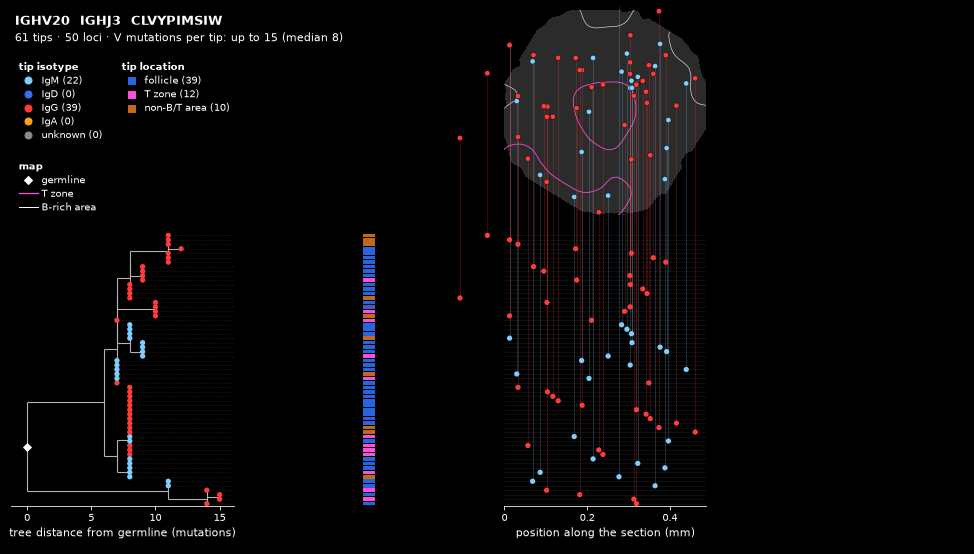

In [5]:
fig = pl.lineage_tree(lin, drawn.tree_id.iloc[0], grouping="exact")
plt.show()

`pl.lineage_gallery` writes one such figure per drawn tree, and an index table:

In [6]:
paths = pl.lineage_gallery(lin, "lineage_gallery_synthetic", dpi=72)
index = pd.read_csv(next(p for p in paths if str(p).endswith(".csv")))
print(len([p for p in paths if str(p).endswith(".png")]), "figures written")
index[["file", "grouping", "rank", "tree_id", "n_tips", "max_mutations", "isotypes", "locations"]].head(6)

12 figures written


,file,grouping,rank,tree_id,n_tips,max_mutations,isotypes,locations
0,lineage_exact_01.png,exact,1,IGHV20|IGHJ3|CLVYPIMSIW,61,15,IgG 39; IgM 22,follicle 39; T zone 12; non-B/T area 10
1,lineage_exact_02.png,exact,2,IGHV2|IGHJ1|CFWHMVNGTYLWDHW,250,8,IgA 109; IgM 73; IgG 68,follicle 163; T zone 49; non-B/T area 38
2,lineage_exact_03.png,exact,3,IGHV16|IGHJ3|CFDVEGIKAHVQW,211,6,IgA 102; IgG 55; IgM 54,follicle 143; T zone 44; non-B/T area 24
3,lineage_exact_04.png,exact,4,IGHV12|IGHJ2|CASQGKGW,39,6,IgG 30; IgM 5; IgA 4,follicle 33; T zone 3; non-B/T area 3
4,lineage_exact_05.png,exact,5,IGHV5|IGHJ4|CFGKDISPGNGNVW,186,4,IgG 91; IgA 81; IgM 14,follicle 133; T zone 31; non-B/T area 22
5,lineage_exact_06.png,exact,6,IGHV26|IGHJ2|CRLLMTYQEKPW,85,4,IgG 37; IgA 26; IgM 22,follicle 66; non-B/T area 11; T zone 8


## 3. The trees against the planted truth

`sim.score_lineages` compares every tree with the lineage planted behind its records:

* `purity`: share of the tree's records from its main planted lineage (1 = the clone grouping is right);
* `tips_exact`: tips whose cleaned sequence carries exactly the planted mutations of their genotype;
  `recovered_mutations` and `false_mutations` count the planted mutations found and the differences that no planted
  genotype carries (sequencing errors that survived the cleaning);
* `rf`, `rf_norm`: Robinson-Foulds distance between the tree and the planted tree on the genotypes it shows (0 = the
  same topology); `depth_cor`: correlation of each tip's distance from the germline in the two trees;
* `tips_in_place`: tips whose records all sit on their own cell. A tip's position is only as good as the receptor
  positions, and on this section 70% of the molecules were swapped.

In [7]:
score = sim.score_lineages(lin, syn)
score[["tree_id", "lineage", "purity", "tips", "tips_exact", "planted_mutations", "recovered_mutations",
       "false_mutations", "rf", "rf_norm", "depth_cor", "tips_in_place"]]

,tree_id,lineage,purity,tips,tips_exact,planted_mutations,recovered_mutations,false_mutations,rf,rf_norm,depth_cor,tips_in_place
0,IGHV12|IGHJ2|CASQGKGW,L00009,1.0,39,39,154,154,0,0.0,0.0,1.000000,7
1,IGHV16|IGHJ3|CFDVEGIKAHVQW,L00002,1.0,211,209,430,430,2,0.0,0.0,1.000000,6
2,IGHV20|IGHJ3|CLVYPIMSIW,L00008,1.0,61,60,550,549,0,0.0,0.0,0.967971,10
3,IGHV26|IGHJ2|CRLLMTYQEKPW,L00000,1.0,85,85,209,209,0,0.0,0.0,1.000000,10
4,IGHV2|IGHJ1|CFWHMVNGTYLWDHW,L00011,1.0,250,244,1221,1221,5,0.0,0.0,0.947331,7
5,IGHV5|IGHJ4|CFGKDISPGNGNVW,L00016,1.0,186,179,330,329,6,0.0,0.0,1.000000,7


In [8]:
pd.Series(score.attrs["summary"])

trees                               6.000000
tips                              832.000000
tips_exact                        816.000000
planted_mutations                2894.000000
recovered_mutations              2892.000000
false_mutations                    13.000000
median_rf_norm                      0.000000
records_full_length              3515.000000
records_exact_mutations             0.993741
errors_in_full_length_records     519.000000
errors_reverted                   501.000000
dtype: float64

*Reading the scores.* Six of the 17 planted lineages with at least two cells got a tree: one of the others has a stop
codon in its junction (not productive), and ten show fewer than five distinct sequences, the workflow's minimum for a
tree (`min_distinct=5`). Every tree holds records of one planted lineage only (purity 1), and all six have the planted
topology on the genotypes they show (Robinson-Foulds distance 0; the distances of the tips from the germline correlate
0.95-1 between the two trees). 816 of the 832 tips (98%) carry exactly the planted mutations of their cells, and 2,892
of the 2,894 planted mutations are recovered. Of the 519 sequencing errors in full-length records, 501 (97%) were
reverted because each was seen in a single spot; the others occurred twice by chance and left 13 false mutations in the
tips. After cleaning, 99.4% of the 3,515 full-length heavy-chain records carry exactly their planted number of
mutations.

What the trees cannot repair is the position of a tip: only 47 of the 832 tips (6%) are made of molecules that sit on
their own cell. On this section 70% of the molecules were swapped to random places, and every swapped molecule becomes
a tip of its own away from its cell, with the right sequence in the wrong place. Read the map of a tree only where the
trust report licenses clone positions (tutorial 01 runs it on this section).

## 4. A public lymph node: one region on its own

The rest of the notebook uses the AIR-SPACE day-21 node. `bcr.hotspot_workflow` finds class-switch (CSR) and
mutation (SHM) hotspots and the regions where they overlap; without an overlap, as on this node, each CSR hotspot
becomes a region (`regions.source == "csr"`), with its clone-level p-values and its transcriptome identity
(tutorials 03 and 07 explain the steps).

In [9]:
sa = spaclone.read(*spaclone.datasets.airspace("D21"))
hot = bcr.hotspot_workflow(sa)
print(hot)
hot.regions[["region_id", "source", "n_loci", "switched_share", "mutated_share", "csr_clone_p", "shm_clone_q",
             "gex_label"]]

HotspotWorkflowResult(3,166 IGH records, 2,791 loci; 3 CSR and 0 SHM hotspots; 3 regions from CSR hotspots: 1: erythroid / ASC (mixed) (clone-level p CSR 0.002, SHM q 0.671); 2: ASC (clone-level p CSR 0.027, SHM q 0.671); 3: ASC (Sdc1+) (clone-level p CSR 0.000999, SHM q 0.301))


,region_id,source,n_loci,switched_share,mutated_share,csr_clone_p,shm_clone_q,gex_label
0,1,csr,111,0.990826,0.351064,0.001998,0.670833,erythroid / ASC (mixed)
1,2,csr,58,0.982759,0.306122,0.026973,0.670833,ASC
2,3,csr,28,1.000000,0.500000,0.000999,0.300570,ASC (Sdc1+)


`pl.region_zoom` draws one region on its own, here the one with the smallest clone-level CSR p: its isotypes, its
mutated loci and the transcriptome module of its identity.

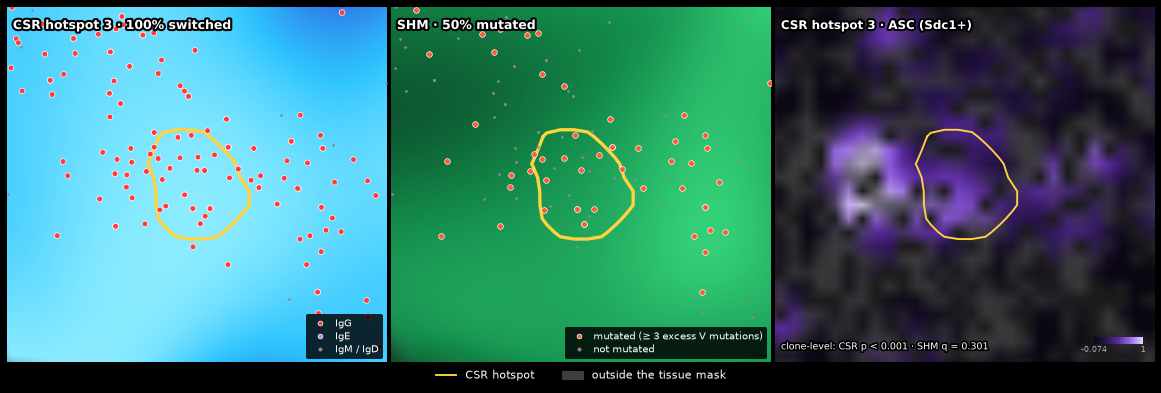

In [10]:
best = hot.regions.sort_values(["csr_clone_p", "n_loci"], ascending=[True, False])["region_id"].iloc[0]
fig = pl.region_zoom(hot, best, dpi=72)
plt.show()

## 5. sciCSR: where does the transition model accumulate?

As in tutorial 07, every tissue bead gets sciCSR's class-switch potential (its isotype's position along the IgH
locus, imputed from neighbours where it has no heavy chain) and its region (germinal centres and the ASC area called
from the transcriptome, `gex.call_regions`); `tl.transition_model` biases each bead's steps towards neighbours of
higher potential, and `tl.tpt_flux` measures the flux from the germinal centres to the ASC area against the potential
permuted within regions. `pl.stationary_distribution` shows where the chain spends its time in the long run, with
bootstrap 95% intervals, beside each region's share of beads: a region whose stationary probability exceeds its share
is one the chain accumulates in.

In [11]:
g = sa.gex.copy()
gex.call_regions(g, kind="germinal_centre")
gex.call_regions(g, kind="asc")
tissue = g[g.obs["in_tissue"].to_numpy(bool)].copy()
records = pp.filter_records(sa.air, valid_junction=True, productive=True, on_tissue=True).air
units = bcr.csr_potential(records[records["spot_id"].astype(str).isin(tissue.obs_names)], unit_key="spot_id",
                          species="mouse")
units["region"] = (tissue.obs["region"].astype(str).replace({"nan": "other"}).reindex(units.index).fillna("other")
                   .to_numpy())
model = tl.transition_model(units, time_key="csr_pot", graph="spatial", states="region", rng=0)
flux = tl.tpt_flux(model, source="GC", target="ASC", rng=0)
print({k: flux.summary[k] for k in ("rate", "rate_null_mean", "rate_p_value")})
flux.states[["n_units", "unit_share", "stationary", "stationary_lo", "stationary_hi"]]

{'rate': 0.03775719299332866, 'rate_null_mean': 0.02978275533814629, 'rate_p_value': 0.009900990099009901}


,n_units,unit_share,stationary,stationary_lo,stationary_hi
state,,,,,
ASC,1113,0.168585,0.264255,0.257984,0.272299
GC,773,0.117086,0.113738,0.109833,0.117773
other,4716,0.714329,0.622007,0.608914,0.631316


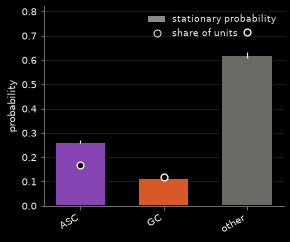

In [12]:
ax = pl.stationary_distribution(flux)
plt.show()

*Reading the stationary distribution.* The chain spends 26% of its time in the ASC area (bootstrap interval 25.8-27.2%),
which holds 17% of the beads, and less than their share in the rest of the node (62% against 71%); the germinal centres
keep about their share (11.4% against 11.7%). A chain whose steps prefer neighbours of higher class-switch potential
accumulates where switched isotypes sit, and on this node that is the ASC area, in line with the flux test above
(reactive paths from the germinal centres to the ASC area at a rate of 0.038 against 0.030 with the potential permuted
within regions, p = 0.0099, the smallest value 100 draws allow). The chain describes where the potential increases on
the tissue, not how cells move.

## 6. Threadfin clone states along the clone axis

`ext.threadfin.run` profiles each expanded clone by the transcriptomes of its beads and orders the clones along axes of
clone-level variation (tutorial 07 maps them on the tissue). Bead types are scored first with the built-in mouse
immune markers, so that the bridge finds the tissue context (T zones, B-rich follicles and the non-B/T area) from them.

In [13]:
typed = sa.gex.copy()
gex.score_cell_types(typed, markers="immune_mouse")
tf = threadfin.run(io.SpatialAIR(sa.air, typed, sa.meta), rng=0)
print(tf)
print(tf.context_note)
pd.Series(tf.summary())

ThreadfinSpatialResult(spot/expression: 2,925 units, 2,925 with a clone, 1,166 clones, 472 profiled; axis 1 63.0%, axis 2 6.4%, axis 3 4.1%)
auto: spatial_context(gex, cell_type_key='cell_type'), the only standard label column (T: T, Tfh; B: ASC, B, GC_B; erythroid: erythroid)


units                      spot
features             expression
n_units                    2925
n_clonal_units             2925
n_clones                   1166
n_profiled_clones           472
n_profiled_units           2231
icc                    0.040933
icc_p                   0.00995
n_programmes                  1
axis_1_share           0.630317
axis_2_share            0.06437
axis_3_share           0.040714
dtype: object

`threadfin.niche_by_axis` cuts the profiled clones into deciles of their axis value and asks, for every compartment,
whether the share of member beads there changes along the axis more than when clone labels are permuted within Ig RNA
depth strata. `pl.clone_axis_profile` draws the shares (solid) against the permutation null (dashed, with its 95%
band).

TestResult(niche_by_axis: axis=1, n_profiled_clones=472, n_units=2231, T zone D1=0.01027, T zone D10=0.004301, trend[T zone]=-0.01815; table 44×15)


,category,statistic,null_mean,p_value,q_value
40,T zone,-0.018147,0.002894,0.37,0.74
41,follicle,-0.084356,-0.090344,0.75,0.93
42,non-B/T area,0.087674,0.088335,0.93,0.93
43,outside,-0.003093,0.022356,0.25,0.74


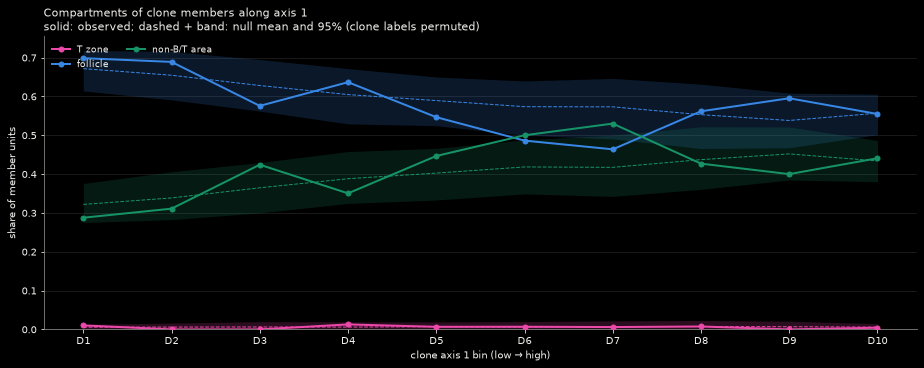

In [14]:
niche = threadfin.niche_by_axis(tf, rng=0)
print(niche)
display(niche.table.query("kind == 'trend'")[["category", "statistic", "null_mean", "p_value", "q_value"]])
fig = pl.clone_axis_profile(tf, niche)
plt.show()

`threadfin.spanning_clones` asks how many expanded clones (at least 5 beads) have members at both ends of the axis
(bottom and top tertile), how spread their members are on the axis and how far apart the two ends lie, against copies
of each clone moved as a rigid body to random places on the node. `pl.spanning_clones` draws the largest spanning
clones, each bead coloured by its own position on the axis and linked by the clone's minimum spanning tree.

TestResult(spanning_clones: axis=1, null=relocate, n_expanded=109, n_spanning=93, tertile_cuts=[-0.1252292351741994, 0.11290326358856481], n_clones_without_valid_relocation=49; table 109×20)


n_expanded                           109.000000
n_spanning                            93.000000
n_clones_without_valid_relocation     49.000000
spanning_share                         0.853211
spanning_share_null                    0.684185
p[spanning_share]                      0.220000
median_axis_range                      0.735208
median_axis_range_null                 0.570278
p[median_axis_range]                   0.040000
dtype: float64

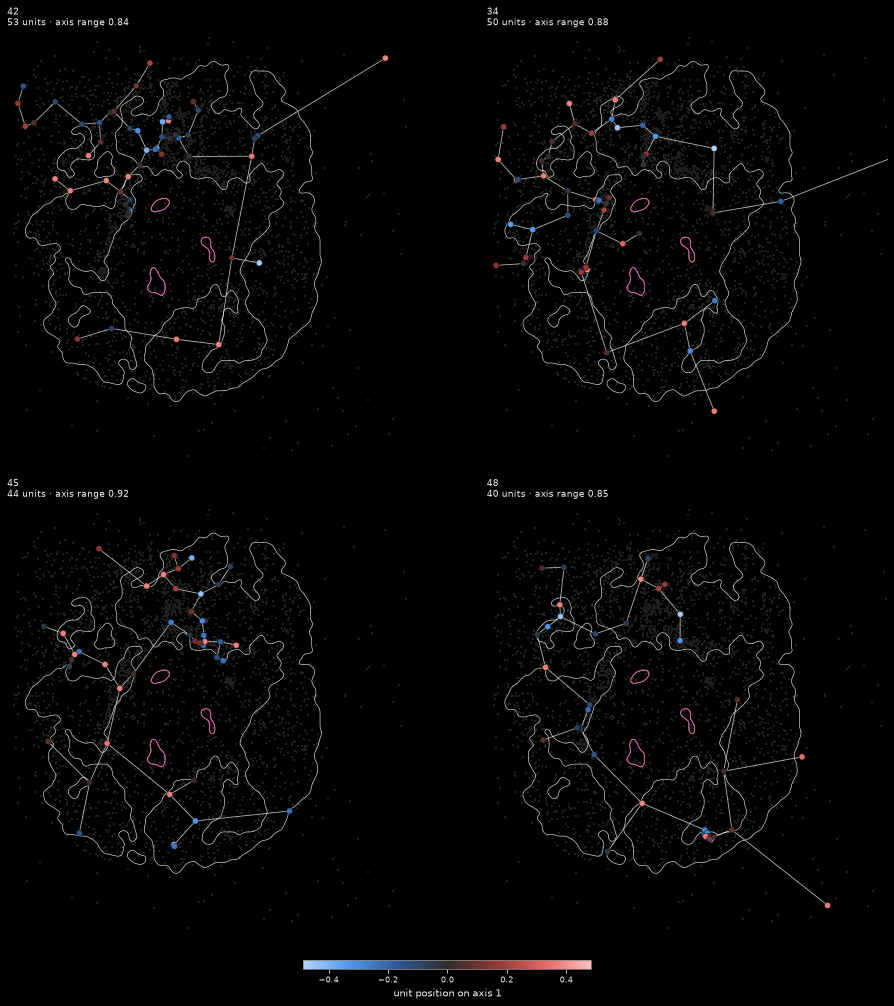

In [15]:
span = threadfin.spanning_clones(tf, rng=0)
print(span)
display(pd.Series({k: span.summary[k] for k in ("n_expanded", "n_spanning", "n_clones_without_valid_relocation",
                                                 "spanning_share", "spanning_share_null", "p[spanning_share]",
                                                 "median_axis_range", "median_axis_range_null",
                                                 "p[median_axis_range]")}))
fig = pl.spanning_clones(tf, span)
plt.show()

*Reading the clone states.* Clone identity explains a small share of the beads' transcriptomes (ICC 0.04, p = 0.01),
and axis 1 carries 63% of the clone-level variance. Along axis 1, no compartment share changes more than with permuted
clone labels (trend q = 0.74 for the T zone, 0.93 for the follicles and the non-B/T area): on this node the clone
axis does not follow the tissue compartments. These q-values come from a run on Python 3.12 with one BLAS thread;
with more threads, or other numpy and scipy versions (Python 3.11), Threadfin's axes change in their last digits and
the T-zone q reads 0.76, with the same conclusion. 93 of the 109 expanded clones (85%) have members at both ends of the axis,
against 68% of their relocated copies (p = 0.22), and their members spread more widely along the axis than those of
relocated copies (median range 0.74 against 0.57, p = 0.04). 49 of the 109 clones, every clone with more than 15 beads
among them, find no place in the node where a rigid copy fits; they have no p-value of their own (the four clones in the
figure are among them), and the summary null covers the other 60.

## Summary

| Function | Data | Result |
|---|---|---|
| `bcr.lineage_workflow`, `pl.lineage_tree`, `pl.lineage_gallery` | synthetic section | 6 exact trees with 832 tips; 12 gallery figures with their index |
| `sim.score_lineages` | synthetic section | planted topology in all 6 trees (Robinson-Foulds 0); 98% of tips with exactly their planted mutations; 97% of sequencing errors reverted; 6% of tips on their own cell |
| `pl.region_zoom` | AIR-SPACE day 21 | CSR hotspot 3: every isotyped locus switched, an ASC area by its transcriptome, clone-level CSR p < 0.001 |
| `pl.stationary_distribution` | AIR-SPACE day 21 | the chain accumulates in the ASC area (26% against 17% of beads) |
| `pl.clone_axis_profile` | AIR-SPACE day 21 | no compartment trend along clone axis 1 (q >= 0.74) |
| `pl.spanning_clones` | AIR-SPACE day 21 | 93 of 109 expanded clones span the axis (relocated copies 68%, p = 0.22) |

**Caveats.** The section of parts 1-3 is simulated: its germline genes are not real immunoglobulin genes, its lineages
follow a coalescent with uniform mutation targeting, and real data add allele uncertainty, indels and 5' truncation
(`truncated_fraction=` simulates the last). The AIR-SPACE beads are 10 µm, so a bead mixes cells; the regions and cell
types are bead-level calls from the transcriptome.